In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile

# extracting the time series of tomato prices without loading the data
zip_path = r"K:\RESEARCH PROJECTS\Prof. Gaurav Arora\price data\csv.zip"

data_pieces = []

with zipfile.ZipFile(zip_path, 'r') as z:
    for year in range(2015, 2026): 
        file_name = f"{year}.csv"
        if file_name in z.namelist():
            with z.open(file_name) as f:
                df_year = pd.read_csv(f, usecols=['State', 'Commodity', 'Arrival_Date', 'Modal_Price', 'Variety'])
                data_pieces.append(df_year)                     
                                  
df = pd.concat(data_pieces, ignore_index=True)

df['State'] = df['State'].str.title().str.strip()
df['Commodity'] = df['Commodity'].str.title().str.strip()
df['Variety'] = df['Variety'].str.title().str.strip()

is_ap = df['State'] == 'Andhra Pradesh'
is_guj = df['State'] == 'Gujarat'
is_tomato = df['Commodity'] == 'Tomato'
is_variety_ap = df['Variety'] == 'Local'
is_variety_guj=df['Variety']== 'Tomato'

df_guj = df[is_guj & is_tomato & is_variety_guj].copy()
df_ap = df[is_ap & is_tomato & is_variety_ap].copy()

df_ap['Arrival_Date'] = pd.to_datetime(df_ap['Arrival_Date'])
df_guj['Arrival_Date'] = pd.to_datetime(df_guj['Arrival_Date'])

# taking average of mandis across Andhra Pradesh to arrive at a daily frequency tomato price series for AP
# used linear interpolation to tackle missing values if the gap is more than 1 day
# else the missing value is set equal to the value recorded on the previous day

# taking average of mandis across Andhra Pradesh to arrive at a daily frequency tomato price series for AP
df_daily_ap = df_ap.groupby('Arrival_Date')['Modal_Price'].mean().reset_index()
df_daily_ap = df_daily_ap.sort_values('Arrival_Date')
df_daily_ap = df_daily_ap.set_index('Arrival_Date')
df_daily_ap = df_daily_ap.asfreq('D')
df_daily_ap['Andhra_Modal_Price'] = df_daily_ap['Modal_Price'].ffill(limit=1)
df_daily_ap['Andhra_Modal_Price'] = df_daily_ap['Andhra_Modal_Price'].interpolate(method='linear')

# taking average of mandis across Gujarat to arrive at a daily frequency tomato price series for Gujarat
df_daily_guj = df_guj.groupby('Arrival_Date')['Modal_Price'].mean().reset_index()
df_daily_guj = df_daily_guj.sort_values('Arrival_Date')
df_daily_guj = df_daily_guj.set_index('Arrival_Date')
df_daily_guj = df_daily_guj.asfreq('D')
df_daily_guj['Gujarat_Modal_Price'] = df_daily_guj['Modal_Price'].ffill(limit=1)
df_daily_guj['Gujarat_Modal_Price'] = df_daily_guj['Gujarat_Modal_Price'].interpolate(method='linear')

# combining both state series into a single daily dataframe
df_daily = pd.concat([df_daily_ap['Andhra_Modal_Price'], df_daily_guj['Gujarat_Modal_Price']], axis=1)

print(df_daily.head(10))
print(len(df_daily))

C:\Users\Kanishk Rathore\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


              Andhra_Modal_Price  Gujarat_Modal_Price
Arrival_Date                                         
2015-01-01            660.000000          1815.000000
2015-01-02            700.000000          1868.750000
2015-01-03            950.000000          1821.000000
2015-01-04            700.000000          1936.666667
2015-01-05            714.285714          1965.000000
2015-01-06            700.000000          1896.000000
2015-01-07            728.571429          1832.000000
2015-01-08            642.857143          1922.000000
2015-01-09            621.428571          2126.000000
2015-01-10            564.285714          2176.000000
4016


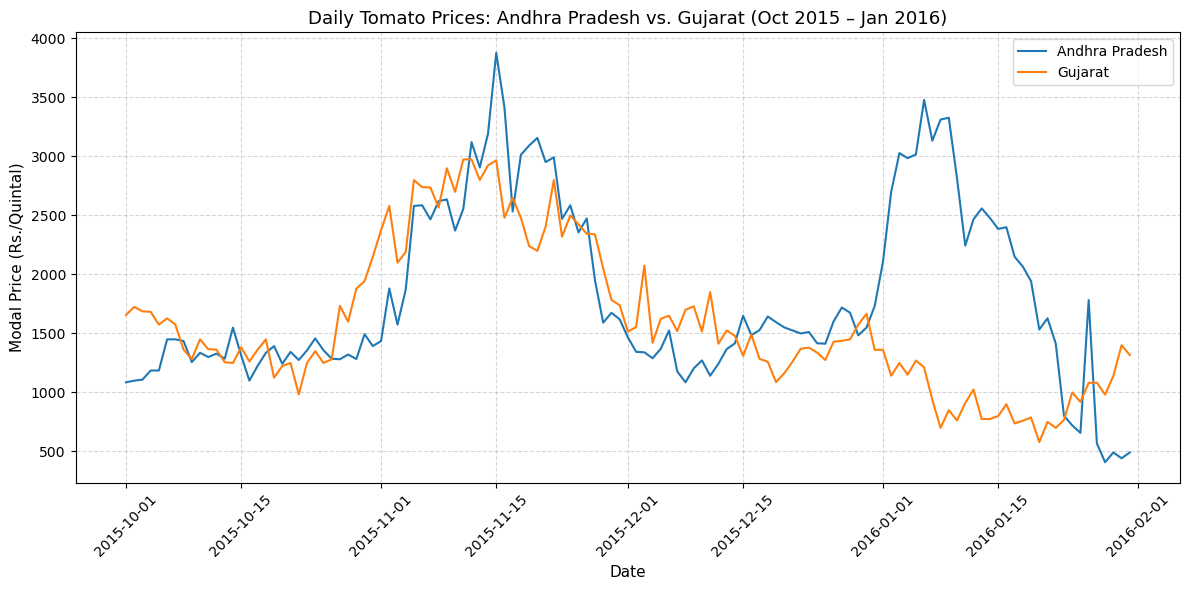

In [2]:
import matplotlib.pyplot as plt

# 1. Filtering the dataframe for the desired date range (1 Oct 2015 to 31 Jan 2016)
start_date = '2015-10-01'
end_date = '2016-01-31'
df_subset = df_daily.loc[start_date:end_date]


plt.figure(figsize=(12, 6))

# 2. Plot both price series on the same graph
plt.plot(df_subset.index, df_subset['Andhra_Modal_Price'], label='Andhra Pradesh', color='tab:blue', linewidth=1.5)
plt.plot(df_subset.index, df_subset['Gujarat_Modal_Price'], label='Gujarat', color='tab:orange', linewidth=1.5)

# 3. Add titles, axis labels, and a legend for clarity
plt.title('Daily Tomato Prices: Andhra Pradesh vs. Gujarat (Oct 2015 – Jan 2016)', fontsize=13)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Modal Price (Rs./Quintal)', fontsize=11)
plt.legend( loc='upper right', fontsize=10)

# 4. Add a light grid and rotate date labels 
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()


plt.show()

In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
import warnings


# 1. ISOLATE THE 4-MONTH EVENT WINDOW (Oct 2015 – Jan 2016)
start_date = '2015-10-01'
end_date = '2016-01-20'
df_window = df_daily.loc[start_date:end_date].copy()



# 2. PREPROCESSING & STATIONARITY FUNCTION

def analyze_short_window_stationarity(df, price_col, state_name):
    print("=" * 65)
    print(f"SHORT-WINDOW STATIONARITY ANALYSIS: {state_name.upper()}")
    print("=" * 65)
    
    # Drop any missing values in the window to ensure clean estimation
    sub_df = df[[price_col]].dropna().copy()
    
    # STEP 1: Log Transformation (Nominal prices -> Natural Log)
    # No WPI deflation is applied because macro inflation is negligible over 120 days
    sub_df['Log_Price'] = np.log(sub_df[price_col])
    
    # STEP 2: Micro-Deseasonalization (Day-of-Week Dummies Only)
    # Extract day of the week (0 = Monday, ..., 6 = Sunday)
    sub_df['DOW'] = sub_df.index.dayofweek
    
    # Create Day-of-Week dummies, dropping Monday (0) as the baseline reference
    dow_dummies = pd.get_dummies(sub_df['DOW'], prefix='DOW', drop_first=True, dtype=int)
    
    # Set up OLS regression: Log_Price = intercept + DOW_Dummies + residual
    X = sm.add_constant(dow_dummies)
    y = sub_df['Log_Price']
    
    ols_model = sm.OLS(y, X).fit()
    
    # Extract the residuals (weekly mandi trading rhythms removed)
    residuals = ols_model.resid
    
    # STEP 3: Stationarity Testing (Constant Only / No Linear Trend)
    
    # --- A. Augmented Dickey-Fuller (ADF) Test ---
    # regression='c' enforces constant only; autolag='AIC' selects optimal lag length
    adf_result = adfuller(residuals, regression='c', autolag='AIC')
    adf_stat = adf_result[0]
    adf_pval = adf_result[1]
    adf_lags = adf_result[2]
    adf_crit_5 = adf_result[4]['5%']
    
    print("\n--- 1. Augmented Dickey-Fuller (ADF) Test ---")
    print("Null Hypothesis (H0): The series has a unit root (NON-STATIONARY).")
    print(f"ADF Statistic      : {adf_stat:.4f}")
    print(f"5% Critical Value  : {adf_crit_5:.4f}")
    print(f"p-value            : {adf_pval:.4f}")
    print(f"AIC Selected Lags  : {adf_lags}")
    
    if adf_pval < 0.05:
        print("-> Result: REJECT the null hypothesis at the 5% level.")
        print("-> Plain English: The ADF test indicates the series is STATIONARY.")
        adf_stationary = True
    else:
        print("-> Result: FAIL TO REJECT the null hypothesis at the 5% level.")
        print("-> Plain English: The ADF test indicates the series has a unit root (NON-STATIONARY).")
        adf_stationary = False

    # --- B. KPSS Test ---
    # regression='c' enforces constant (level stationarity) with no time trend
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_result = kpss(residuals, regression='c', nlags='auto')
        
    kpss_stat = kpss_result[0]
    kpss_pval = kpss_result[1]
    kpss_lags = kpss_result[2]
    kpss_crit_5 = kpss_result[3]['5%']
    
    print("\n--- 2. KPSS Test ---")
    print("Null Hypothesis (H0): The series is level-stationary (STATIONARY).")
    print(f"KPSS Statistic     : {kpss_stat:.4f}")
    print(f"5% Critical Value  : {kpss_crit_5:.4f}")
    print(f"p-value            : {kpss_pval:.4f} (Note: statsmodels caps KPSS p-values between 0.01 and 0.10)")
    print(f"Selected Lags      : {kpss_lags}")
    
    # Using the 5% critical value (0.463) for an exact decision rule
    if kpss_stat > kpss_crit_5:
        print("-> Result: REJECT the null hypothesis at the 5% level (Stat > 5% Critical Value).")
        print("-> Plain English: The KPSS test indicates the series is NON-STATIONARY.")
        kpss_stationary = False
    else:
        print("-> Result: FAIL TO REJECT the null hypothesis at the 5% level (Stat <= 5% Critical Value).")
        print("-> Plain English: The KPSS test indicates the series is STATIONARY.")
        kpss_stationary = True

 
    if adf_stationary and kpss_stationary:
        print(f"Both tests agree: {state_name} deseasonalized log prices are strictly STATIONARY I(0).")
    elif not adf_stationary and not kpss_stationary:
        print(f"Both tests agree: {state_name} deseasonalized log prices are NON-STATIONARY I(1).")
    elif not adf_stationary and kpss_stationary:
        print("Tests disagree (ADF fails to reject unit root; KPSS fails to reject stationarity).")
        print("This commonly happens in short 90-120 day samples due to lower statistical power.")
    else:
        print("Tests disagree (ADF rejects unit root; KPSS rejects stationarity).")
        print("This often points to fractional integration I(d) or a structural break/price shock in the window.")
    
    print("\n")
    return residuals



# 3. RUN THE ANALYSIS FOR BOTH STATES
df_window['AP_Resid'] = analyze_short_window_stationarity(
    df_window, 'Andhra_Modal_Price', 'Andhra Pradesh'
)

df_window['Guj_Resid'] = analyze_short_window_stationarity(
    df_window, 'Gujarat_Modal_Price', 'Gujarat'
)

SHORT-WINDOW STATIONARITY ANALYSIS: ANDHRA PRADESH

--- 1. Augmented Dickey-Fuller (ADF) Test ---
Null Hypothesis (H0): The series has a unit root (NON-STATIONARY).
ADF Statistic      : -2.4640
5% Critical Value  : -2.8895
p-value            : 0.1245
AIC Selected Lags  : 6
-> Result: FAIL TO REJECT the null hypothesis at the 5% level.
-> Plain English: The ADF test indicates the series has a unit root (NON-STATIONARY).

--- 2. KPSS Test ---
Null Hypothesis (H0): The series is level-stationary (STATIONARY).
KPSS Statistic     : 0.3616
5% Critical Value  : 0.4630
p-value            : 0.0937 (Note: statsmodels caps KPSS p-values between 0.01 and 0.10)
Selected Lags      : 6
-> Result: FAIL TO REJECT the null hypothesis at the 5% level (Stat <= 5% Critical Value).
-> Plain English: The KPSS test indicates the series is STATIONARY.
Tests disagree (ADF fails to reject unit root; KPSS fails to reject stationarity).
This commonly happens in short 90-120 day samples due to lower statistical pow

C:\Users\Kanishk Rathore\AppData\Local\Temp\ipykernel_2248\2532850642.py:49: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, regression='c', autolag='AIC')
C:\Users\Kanishk Rathore\AppData\Local\Temp\ipykernel_2248\2532850642.py:49: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, regression='c', autolag='AIC')


FIRST-DIFFERENCE ADF VERIFICATION: ANDHRA PRADESH (ΔP_AP)
Null Hypothesis (H0): The differenced series has a unit root (NON-STATIONARY).
ADF Statistic      : -5.1242
5% Critical Value  : -2.8887
p-value            : 0.0000
AIC Selected Lags  : 2
-> Result: REJECT the null hypothesis at the 5% significance level.
-> Plain English: The differenced series for Andhra Pradesh (Δp_AP) is strictly stationary I(0) and ready for VAR modeling.

FIRST-DIFFERENCE ADF VERIFICATION: GUJARAT (ΔP_GJ)
Null Hypothesis (H0): The differenced series has a unit root (NON-STATIONARY).
ADF Statistic      : -6.0385
5% Critical Value  : -2.8887
p-value            : 0.0000
AIC Selected Lags  : 2
-> Result: REJECT the null hypothesis at the 5% significance level.
-> Plain English: The differenced series for Gujarat (Δp_GJ) is strictly stationary I(0) and ready for VAR modeling.

VECTOR AUTOREGRESSION (VAR) ESTIMATION
--- Lag Order Selection Table ---
 VAR Order Selection (* highlights the minimums)  
       AIC  

C:\Users\Kanishk Rathore\AppData\Local\Temp\ipykernel_2248\747939905.py:36: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(series, regression='c', autolag='AIC')
C:\Users\Kanishk Rathore\AppData\Local\Temp\ipykernel_2248\747939905.py:36: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(series, regression='c', autolag='AIC')


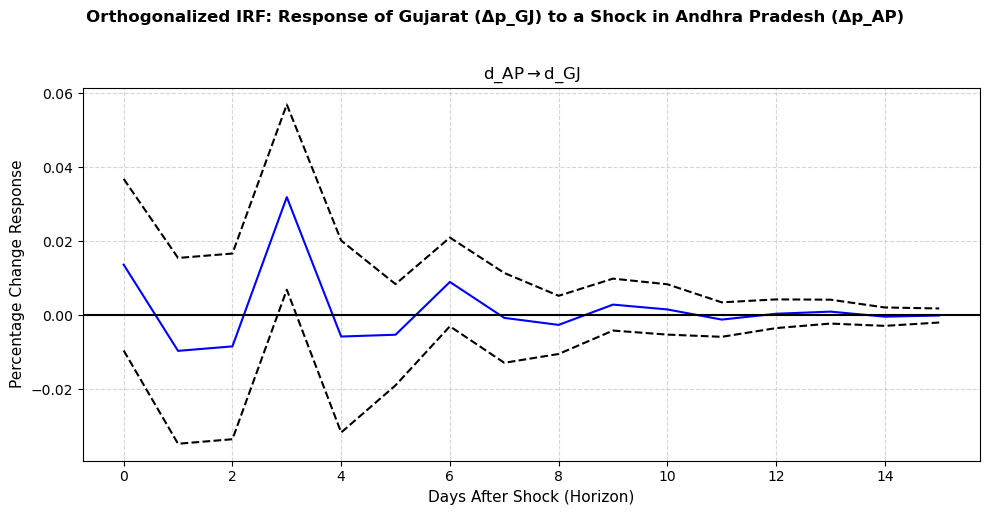

FORECAST ERROR VARIANCE DECOMPOSITION (FEVD) SUMMARY
FEVD for d_AP
          d_AP      d_GJ
0     1.000000  0.000000
1     0.996722  0.003278
2     0.996306  0.003694
3     0.896549  0.103451
4     0.885795  0.114205
5     0.878947  0.121053
6     0.874411  0.125589
7     0.874314  0.125686
8     0.873647  0.126353
9     0.872904  0.127096
10    0.872196  0.127804
11    0.872174  0.127826
12    0.872172  0.127828
13    0.872060  0.127940
14    0.872063  0.127937

FEVD for d_GJ
          d_AP      d_GJ
0     0.012386  0.987614
1     0.016518  0.983482
2     0.020594  0.979406
3     0.074998  0.925002
4     0.074511  0.925489
5     0.075717  0.924283
6     0.079301  0.920699
7     0.079321  0.920679
8     0.079647  0.920353
9     0.080026  0.919974
10    0.080145  0.919855
11    0.080203  0.919797
12    0.080207  0.919793
13    0.080250  0.919750
14    0.080256  0.919744




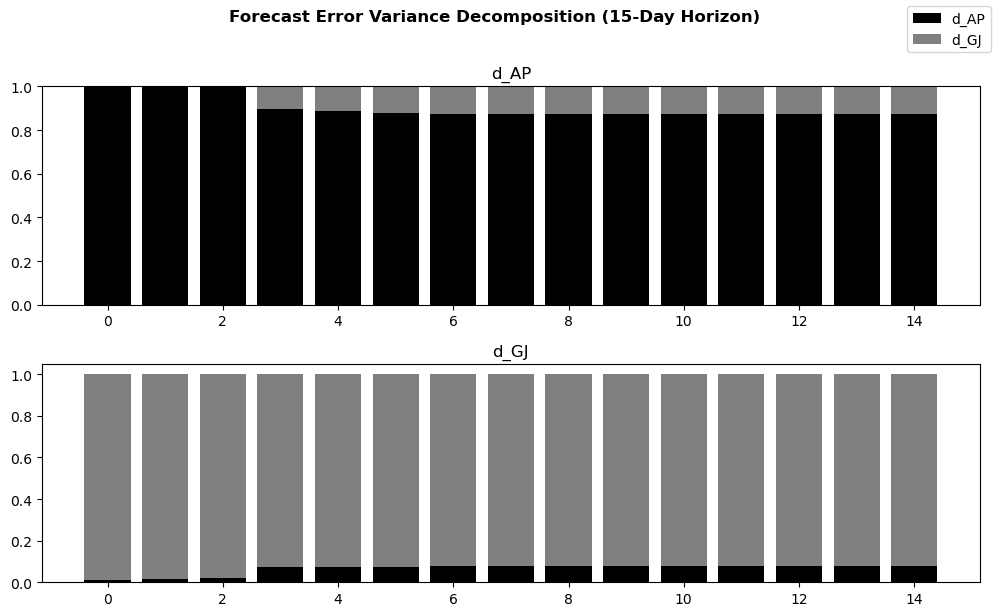

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR


# 1. FIRST DIFFERENCING (CONVERTING I(1) LEVELS TO I(0) RETURNS)

# Econometric Intuition: 
# Since the deseasonalized log price levels are treated as non-stationary I(1), 
# running a VAR directly on levels risks spurious regression. Taking the first 
# difference  transforms the series into daily percentage price changes (log returns).

# Creating a clean dataframe containing the deseasonalized log prices from the prior step
df_var_input = df_window[['AP_Resid', 'Guj_Resid']].copy()
df_var_input.columns = ['AP_Price_Level', 'GJ_Price_Level']

# Take the first difference (.diff()) and drop the initial NaN row
df_diff = df_var_input.diff().dropna()
df_diff.columns = ['d_AP', 'd_GJ']

# Ensure the datetime index explicitly carries a daily frequency ('D') for statsmodels
df_diff.index.freq = 'D'



# 2. STATIONARITY VERIFICATION ON DIFFERENCED SERIES (ADF TEST)

def verify_differenced_stationarity(series, state_name):
    print("=" * 65)
    print(f"FIRST-DIFFERENCE ADF VERIFICATION: {state_name.upper()}")
    print("=" * 65)
    
    # Run ADF test with constant only ('c') and automatic AIC lag selection
    adf_res = adfuller(series, regression='c', autolag='AIC')
    adf_stat = adf_res[0]
    adf_pval = adf_res[1]
    adf_lags = adf_res[2]
    adf_crit_5 = adf_res[4]['5%']
    
    print("Null Hypothesis (H0): The differenced series has a unit root (NON-STATIONARY).")
    print(f"ADF Statistic      : {adf_stat:.4f}")
    print(f"5% Critical Value  : {adf_crit_5:.4f}")
    print(f"p-value            : {adf_pval:.4f}")
    print(f"AIC Selected Lags  : {adf_lags}")
    
    if adf_pval < 0.05:
        print("-> Result: REJECT the null hypothesis at the 5% significance level.")
        print(f"-> Plain English: The differenced series for {state_name} is strictly stationary I(0) and ready for VAR modeling.\n")
    else:
        print("-> Result: FAIL TO REJECT the null hypothesis at the 5% significance level.")
        print(f"-> Plain English: The differenced series for {state_name} still exhibits non-stationarity. Check for extreme outliers.\n")

# Verify both differenced series
verify_differenced_stationarity(df_diff['d_AP'], 'Andhra Pradesh (Δp_AP)')
verify_differenced_stationarity(df_diff['d_GJ'], 'Gujarat (Δp_GJ)')



# 3. VECTOR AUTOREGRESSION (VAR) MODEL ESTIMATION

# Econometric Intuition:
# A VAR model treats both states' price changes as endogenous, capturing how 
# today's price movement in Gujarat depends on past price movements in both 
# Gujarat and Andhra Pradesh (spatial price transmission across mandis).
# Note on Cholesky Ordering: Putting 'd_AP' first in the dataframe implies 
# that a supply/price shock in Andhra Pradesh can affect Gujarat contemporaneously 
# (within the same day), while Gujarat affects AP with at least a 1-day lag.

print("=" * 65)
print("VECTOR AUTOREGRESSION (VAR) ESTIMATION")
print("=" * 65)

# Initialize the VAR model with the stationary differenced dataframe
# Ordering: ['d_AP', 'd_GJ'] -> AP is ordered first for Cholesky decomposition
var_model = VAR(df_diff[['d_AP', 'd_GJ']])

# Automatically select the optimal lag order using AIC (setting maxlags=10 for a 120-day sample)
lag_selection = var_model.select_order(maxlags=10)
print("--- Lag Order Selection Table ---")
print(lag_selection.summary())

# Fit the VAR model using the AIC-optimal lag length
optimal_lags = lag_selection.aic
# Fallback to 1 lag in case AIC selects 0 lags (since VAR requires at least 1 lag for dynamics)
if optimal_lags == 0:
    print("\nNote: AIC selected 0 lags. Defaulting to 1 lag to allow dynamic VAR estimation.")
    optimal_lags = 1

var_fitted = var_model.fit(optimal_lags)

print(f"\n-> Selected Optimal Lag Length (AIC): {var_fitted.k_ar} lag(s)")
print("\n--- Brief VAR Model Summary ---")
print(var_fitted.summary())



# 4. STRUCTURAL ANALYSIS: ORTHOGONALIZED IRF & FEVD


# --- A. Orthogonalized Impulse Response Function (IRF) ---
# Econometric Intuition:
# The IRF traces out the dynamic path of Gujarat's tomato returns over the next 
# 15 days following a 1-standard-deviation shock to Andhra Pradesh's returns at day 0.
# Using `orth=True` applies a Cholesky decomposition to isolate pure, uncorrelated shocks.

horizon = 15
irf = var_fitted.irf(periods=horizon)

# Plot specifically how a shock in 'd_AP' (impulse) transmits to 'd_GJ' (response)
fig_irf = irf.plot(impulse='d_AP', response='d_GJ', orth=True, figsize=(10, 5))
plt.suptitle("Orthogonalized IRF: Response of Gujarat (Δp_GJ) to a Shock in Andhra Pradesh (Δp_AP)", 
             fontsize=12, fontweight='bold', y=1.02)
plt.xlabel("Days After Shock (Horizon)", fontsize=11)
plt.ylabel("Percentage Change Response", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# --- B. Forecast Error Variance Decomposition (FEVD) ---
# Econometric Intuition:
# While the IRF shows the direction and magnitude of a shock over time, the FEVD 
# measures the relative importance of each state's shock. It breaks down what 
# percentage (0% to 100%) of the unexpected variation in Gujarat's prices over 
# a 15-day forecast horizon is driven by Andhra Pradesh vs. Gujarat's own local shocks.

fevd = var_fitted.fevd(periods=horizon)

print("=" * 65)
print("FORECAST ERROR VARIANCE DECOMPOSITION (FEVD) SUMMARY")
print("=" * 65)
# Print the numerical decomposition table
fevd.summary()

# Plot the FEVD stacked bar/area chart for both variables over the 15-day horizon
fig_fevd = fevd.plot(figsize=(10, 6))
plt.suptitle("Forecast Error Variance Decomposition (15-Day Horizon)", 
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

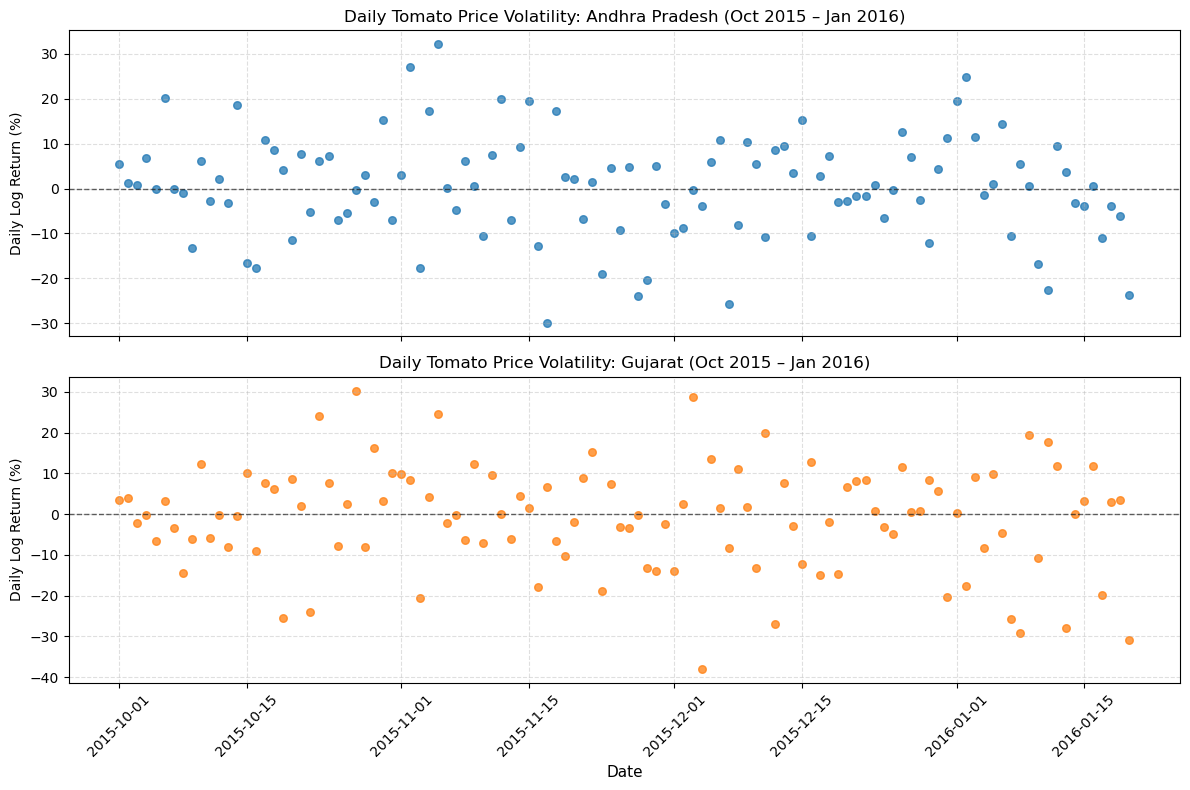

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Calculate daily log returns (daily price volatility/swings)
# Multiplying by 100 expresses the daily volatility as a percentage change
df_daily['AP_Volatility'] = np.log(df_daily['Andhra_Modal_Price']).diff() * 100
df_daily['Guj_Volatility'] = np.log(df_daily['Gujarat_Modal_Price']).diff() * 100

# 2. Slice the dataframe for the Oct 2015 – Jan 2016 window
df_vol_window = df_daily.loc['2015-10-01':'2016-01-20'].copy()

# 3. Create two separate scatter plots (stacked vertically)
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8), sharex=True)

# --- Graph 1: Andhra Pradesh Volatility ---
axes[0].scatter(
    df_vol_window.index, 
    df_vol_window['AP_Volatility'], 
    color='tab:blue', 
    alpha=0.75, 
    s=30
)
axes[0].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.6)
axes[0].set_title('Daily Tomato Price Volatility: Andhra Pradesh (Oct 2015 – Jan 2016)', fontsize=12)
axes[0].set_ylabel('Daily Log Return (%)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.4)

# --- Graph 2: Gujarat Volatility ---
axes[1].scatter(
    df_vol_window.index, 
    df_vol_window['Guj_Volatility'], 
    color='tab:orange', 
    alpha=0.75, 
    s=30
)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.6)
axes[1].set_title('Daily Tomato Price Volatility: Gujarat (Oct 2015 – Jan 2016)', fontsize=12)
axes[1].set_xlabel('Date', fontsize=11)
axes[1].set_ylabel('Daily Log Return (%)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.4)

# Clean up date labels and spacing
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

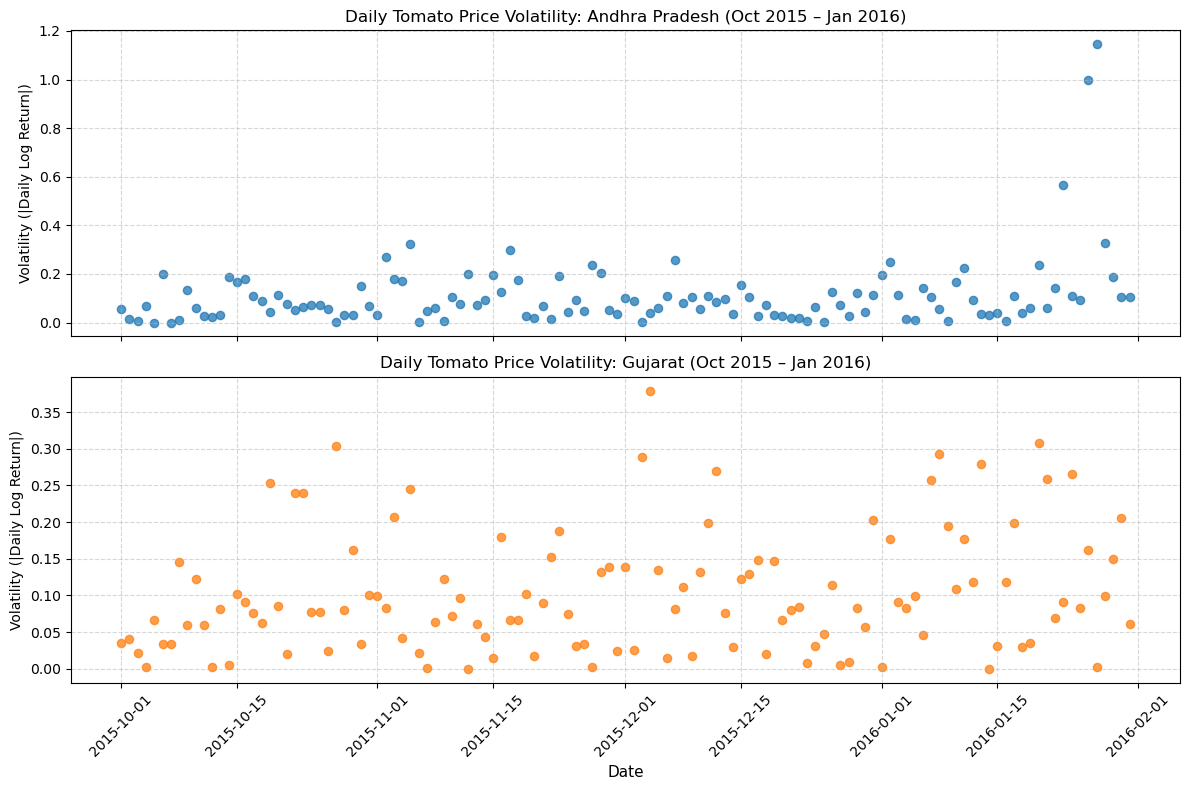

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Isolate the Oct 2015 - Jan 2016 window (starting 1 day early so Oct 1 has a return)
df_vol = df_daily.loc['2015-09-30':'2016-01-31'].copy()

# 2. Calculate daily volatility as the absolute daily log return: |ln(P_t) - ln(P_{t-1})|
df_vol['AP_Volatility'] = np.log(df_vol['Andhra_Modal_Price']).diff().abs()
df_vol['GJ_Volatility'] = np.log(df_vol['Gujarat_Modal_Price']).diff().abs()

# Drop the extra Sept 30 row so the plot strictly starts on Oct 1, 2015
df_vol = df_vol.loc['2015-10-01':'2016-01-31']

# 3. Set up two separate side-by-side (or stacked) subplots
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(12, 8), sharex=True)

# --- Graph 1: Andhra Pradesh Scatter Plot ---
ax1.scatter(df_vol.index, df_vol['AP_Volatility'], color='tab:blue', alpha=0.75, s=35)
ax1.set_title('Daily Tomato Price Volatility (calculated as absolute daily log return): Andhra Pradesh (Oct 2015 – Jan 2016)', fontsize=12)
ax1.set_ylabel('Volatility (|Daily Log Return|)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Graph 2: Gujarat Scatter Plot ---
ax2.scatter(df_vol.index, df_vol['GJ_Volatility'], color='tab:orange', alpha=0.75, s=35)
ax2.set_title('Daily Tomato Price Volatility: Gujarat (Oct 2015 – Jan 2016)', fontsize=12)
ax2.set_xlabel('Date', fontsize=11)
ax2.set_ylabel('Volatility (|Daily Log Return|)', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

# Format the x-axis dates cleanly and display both graphs
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [3]:
pip install arch 

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------------------------------ --------- 1.0/1.4 MB 5.9 MB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 5.9 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


GARCH(1,1) VOLATILITY FILTER: ANDHRA PRADESH
Alpha (Shock Effect)       : 0.1688
Beta (Persistence)         : 0.0000
Median Daily Volatility    : 10.75%
Pre-Filter ARCH-LM p-val   : 0.1599
Post-Filter ARCH-LM p-val  : 0.2506
-> Verdict: Volatility clustering removed (Constant variance restored).

GARCH(1,1) VOLATILITY FILTER: GUJARAT
Alpha (Shock Effect)       : 0.1018
Beta (Persistence)         : 0.7574
Median Daily Volatility    : 12.70%
Pre-Filter ARCH-LM p-val   : 0.6915
Post-Filter ARCH-LM p-val  : 0.7156
-> Verdict: Volatility clustering removed (Constant variance restored).

STATIONARITY CHECK: Andhra Pradesh (z_AP)
ADF Stat : -2.6772 | p-val: 0.0781 | Lags: 7
-> ADF Verdict : NON-STATIONARY
KPSS Stat: 0.1949 | 5% Crit: 0.4630 | Lags: 2
-> KPSS Verdict: STATIONARY I(0)

STATIONARITY CHECK: Gujarat (z_GJ)
ADF Stat : -6.0287 | p-val: 0.0000 | Lags: 2
-> ADF Verdict : STATIONARY I(0)
KPSS Stat: 0.2864 | 5% Crit: 0.4630 | Lags: 10
-> KPSS Verdict: STATIONARY I(0)

VECTOR AUTOREGRESS

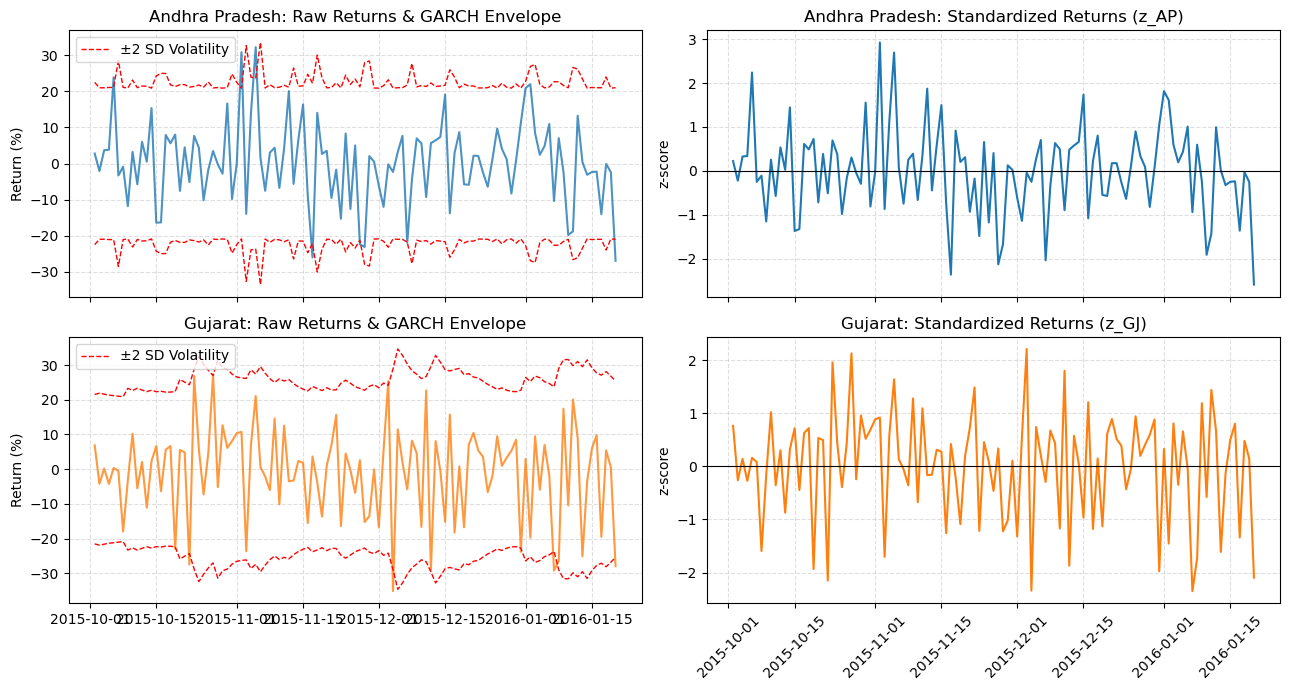

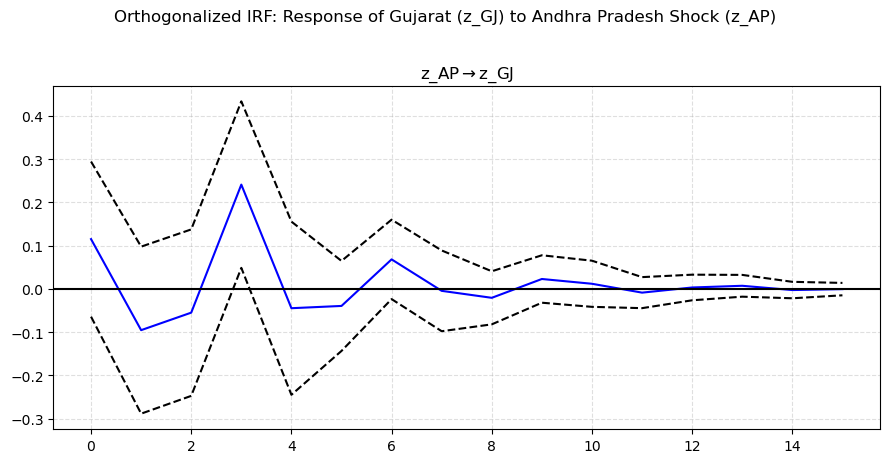

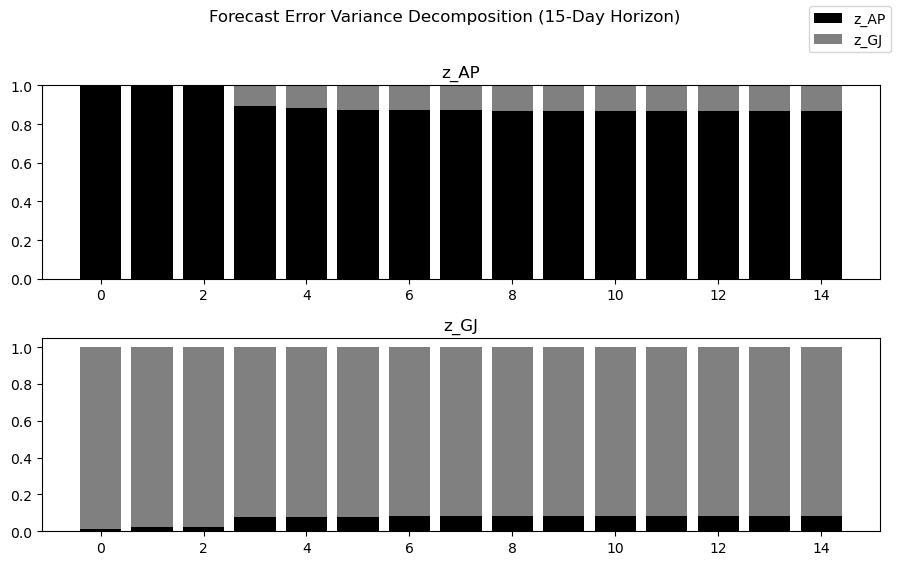

In [5]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.api import VAR
from statsmodels.stats.diagnostic import het_arch

warnings.filterwarnings("ignore")

# Prepare the input dataframe from your previous differencing step
data = df_diff[['d_AP', 'd_GJ']].dropna().copy()


# STEP 1: GARCH(1,1) VOLATILITY FILTERING
# Econometric Intuition: Agricultural returns often show volatility clustering 
# (calm periods followed by big price swings). Dividing raw returns by their 
# daily GARCH volatility gives us clean "standardized returns" (z-scores) 
# with stable variance, preventing extreme price spikes from distorting the VAR.

def apply_garch_filter(series, state_name):
    # Scale decimal returns to percentages (* 100) so the optimizer converges smoothly
    y = series * 100 if series.std() < 1.0 else series.copy()
    
    # Fit a GARCH(1,1) model with a Student's t-distribution to handle fat tails
    model = arch_model(y, mean='Constant', vol='Garch', p=1, q=1, dist='t', rescale=False)
    res = model.fit(disp='off')
    
    # Extract daily volatility (sigma_t) and standardized residuals (z_t)
    cond_vol = res.conditional_volatility
    std_resid = res.std_resid
    
    # Run ARCH-LM test (5 lags) before and after filtering to check if volatility clustering is gone
    lm_raw, p_raw, _, _ = het_arch(y, nlags=5)
    lm_std, p_std, _, _ = het_arch(std_resid, nlags=5)
    
    print("=" * 65)
    print(f"GARCH(1,1) VOLATILITY FILTER: {state_name.upper()}")
    print("=" * 65)
    print(f"Alpha (Shock Effect)       : {res.params['alpha[1]']:.4f}")
    print(f"Beta (Persistence)         : {res.params['beta[1]']:.4f}")
    print(f"Median Daily Volatility    : {cond_vol.median():.2f}%")
    print(f"Pre-Filter ARCH-LM p-val   : {p_raw:.4f}")
    print(f"Post-Filter ARCH-LM p-val  : {p_std:.4f}")
    
    if p_std >= 0.05:
        print("-> Verdict: Volatility clustering removed (Constant variance restored).\n")
    else:
        print("-> Verdict: Variance stabilized (some extreme outliers remain).\n")
        
    return std_resid, cond_vol, y

# Filter both states and store the standardized returns (AP ordered first for Cholesky)
z_AP, vol_AP, y_AP = apply_garch_filter(data['d_AP'], 'Andhra Pradesh')
z_GJ, vol_GJ, y_GJ = apply_garch_filter(data['d_GJ'], 'Gujarat')

df_z = pd.DataFrame({'z_AP': z_AP, 'z_GJ': z_GJ}).dropna()
df_z.index.freq = 'D'


# STEP 2: STATIONARITY CHECKS ON STANDARDIZED SERIES (ADF & KPSS)
def check_stationarity(series, label):
    print("=" * 65)
    print(f"STATIONARITY CHECK: {label}")
    print("=" * 65)
    
    # ADF Test (Null: Non-Stationary)
    adf_stat, adf_p, adf_lags, _, adf_crit, _ = adfuller(series, regression='c', autolag='AIC')
    print(f"ADF Stat : {adf_stat:.4f} | p-val: {adf_p:.4f} | Lags: {adf_lags}")
    print(f"-> ADF Verdict : {'STATIONARY I(0)' if adf_p < 0.05 else 'NON-STATIONARY'}")
    
    # KPSS Test (Null: Stationary)
    kpss_stat, kpss_p, kpss_lags, kpss_crit = kpss(series, regression='c', nlags='auto')
    print(f"KPSS Stat: {kpss_stat:.4f} | 5% Crit: {kpss_crit['5%']:.4f} | Lags: {kpss_lags}")
    print(f"-> KPSS Verdict: {'STATIONARY I(0)' if kpss_stat <= kpss_crit['5%'] else 'NON-STATIONARY'}\n")

check_stationarity(df_z['z_AP'], 'Andhra Pradesh (z_AP)')
check_stationarity(df_z['z_GJ'], 'Gujarat (z_GJ)')



# STEP 3: FIT THE VOLATILITY-STANDARDIZED VAR MODEL
print("=" * 65)
print("VECTOR AUTOREGRESSION (VAR) ESTIMATION")
print("=" * 65)

var_model = VAR(df_z)
lag_results = var_model.select_order(maxlags=10)
print(lag_results.summary())

# Pick the optimal lag using AIC (default to 2 lags if AIC picks 0)
best_lag = lag_results.aic if lag_results.aic > 0 else 2
print(f"\n-> Fitting VAR with {best_lag} lag(s)")

var_fitted = var_model.fit(best_lag)
print(var_fitted.summary())



# STEP 4: GRANGER CAUSALITY & ELASTICITY CONVERSION
# ==============================================================================
print("=" * 65)
print("GRANGER CAUSALITY & ELASTICITY")
print("=" * 65)

# Test 1: Does AP Granger-cause GJ?
gc_ap_to_gj = var_fitted.test_causality(caused='z_GJ', causing=['z_AP'], kind='f')
print(f"1. AP -> GJ : F-stat = {gc_ap_to_gj.test_statistic:.4f}, p-val = {gc_ap_to_gj.pvalue:.4f}")

# Test 2: Does GJ Granger-cause AP? (Reverse causality check)
gc_gj_to_ap = var_fitted.test_causality(caused='z_AP', causing=['z_GJ'], kind='f')
print(f"2. GJ -> AP : F-stat = {gc_gj_to_ap.test_statistic:.4f}, p-val = {gc_gj_to_ap.pvalue:.4f}")

# Elasticity conversion factor (to convert z-score responses back to % returns)
vol_ratio = vol_GJ.median() / vol_AP.median()
print(f"\n-> Implied Elasticity Factor (Med_Vol_GJ / Med_Vol_AP): {vol_ratio:.4f}\n")


# ==============================================================================
# STEP 5: FORECAST ERROR VARIANCE DECOMPOSITION (FEVD)
# ==============================================================================
horizon = 15
fevd = var_fitted.fevd(horizon)
print("=" * 65)
print(f"FEVD SUMMARY ({horizon}-DAY HORIZON)")
print("=" * 65)
fevd.summary()


# ==============================================================================
# STEP 6: VISUALIZATIONS (GARCH ENVELOPE, IRF, & FEVD)
# ==============================================================================
# Plot 1: Raw Returns vs. Standardized Returns
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)

# Andhra Pradesh plots
axes[0, 0].plot(y_AP.index, y_AP, color='tab:blue', alpha=0.8)
axes[0, 0].plot(vol_AP.index, 2 * vol_AP, color='red', linestyle='--', lw=1, label='±2 SD Volatility')
axes[0, 0].plot(vol_AP.index, -2 * vol_AP, color='red', linestyle='--', lw=1)
axes[0, 0].set_title('Andhra Pradesh: Raw Returns & GARCH Envelope')
axes[0, 0].set_ylabel('Return (%)')
axes[0, 0].legend(loc='upper left')
axes[0, 0].grid(True, linestyle='--', alpha=0.4)

axes[0, 1].plot(df_z.index, df_z['z_AP'], color='tab:blue')
axes[0, 1].axhline(0, color='black', lw=0.8)
axes[0, 1].set_title('Andhra Pradesh: Standardized Returns (z_AP)')
axes[0, 1].set_ylabel('z-score')
axes[0, 1].grid(True, linestyle='--', alpha=0.4)

# Gujarat plots
axes[1, 0].plot(y_GJ.index, y_GJ, color='tab:orange', alpha=0.8)
axes[1, 0].plot(vol_GJ.index, 2 * vol_GJ, color='red', linestyle='--', lw=1, label='±2 SD Volatility')
axes[1, 0].plot(vol_GJ.index, -2 * vol_GJ, color='red', linestyle='--', lw=1)
axes[1, 0].set_title('Gujarat: Raw Returns & GARCH Envelope')
axes[1, 0].set_ylabel('Return (%)')
axes[1, 0].legend(loc='upper left')
axes[1, 0].grid(True, linestyle='--', alpha=0.4)

axes[1, 1].plot(df_z.index, df_z['z_GJ'], color='tab:orange')
axes[1, 1].axhline(0, color='black', lw=0.8)
axes[1, 1].set_title('Gujarat: Standardized Returns (z_GJ)')
axes[1, 1].set_ylabel('z-score')
axes[1, 1].grid(True, linestyle='--', alpha=0.4)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 2: Orthogonalized Impulse Response Function (z_AP -> z_GJ)
irf = var_fitted.irf(horizon)
fig_irf = irf.plot(impulse='z_AP', response='z_GJ', orth=True, figsize=(9, 4.5))
plt.suptitle('Orthogonalized IRF: Response of Gujarat (z_GJ) to Andhra Pradesh Shock (z_AP)', y=1.02)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Plot 3: FEVD Chart
fig_fevd = fevd.plot(figsize=(9, 5.5))
plt.suptitle(f'Forecast Error Variance Decomposition ({horizon}-Day Horizon)', y=1.02)
plt.tight_layout()
plt.show()